# 05 · Name & surname lookup

Interactive-style lookup: change `QUERY` (a name, a surname or both) and run the
cells. Shows the rank, frequency and percent, plus a chart with the neighbours
in the ranking. All charts are embedded in the notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in test/; the datasets live in ../data/
DATA = Path("..") / "data"
NOMES_PATH = DATA / "nomes_censo2022_nomes.jsonl"
SOBRENOMES_PATH = DATA / "nomes_censo2022_sobrenomes.jsonl"
POP_BR_2022 = 203_080_756

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def load_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])

print("nomes:     ", NOMES_PATH.resolve())
print("sobrenomes:", SOBRENOMES_PATH.resolve())


nomes:      /home/user/nomescenso2022/data/nomes_censo2022_nomes.jsonl
sobrenomes: /home/user/nomescenso2022/data/nomes_censo2022_sobrenomes.jsonl


In [2]:
nomes = load_jsonl(NOMES_PATH)
sob = load_jsonl(SOBRENOMES_PATH)
nomes.set_index("nome", inplace=True, drop=False)
sob.set_index("nome", inplace=True, drop=False)

QUERY = ["maria", "joao", "silva", "pereira"]   # <- edit me


[nome] Maria: rank 1, frequência 12,284,478, 6.0491% da população


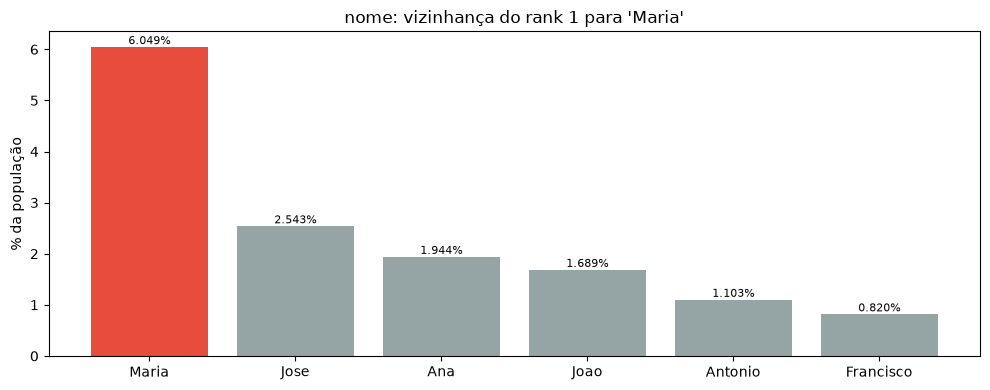

[sobrenome] Maria: rank 53, frequência 970,996, 0.4781% da população


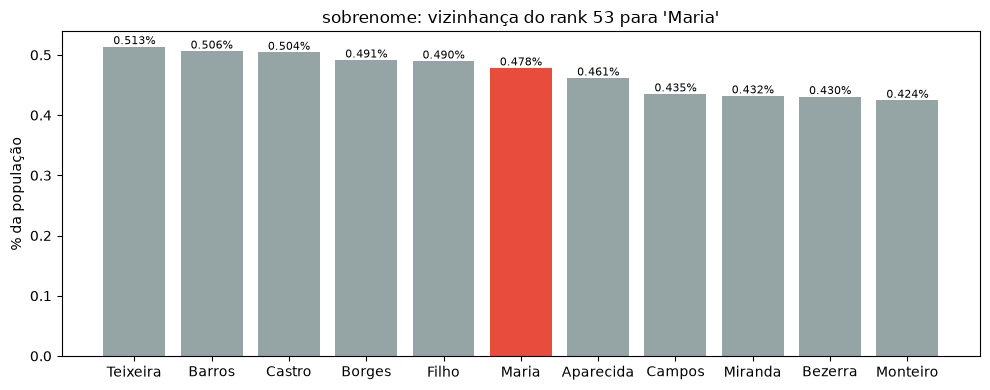

[nome] Joao: rank 4, frequência 3,430,608, 1.6893% da população


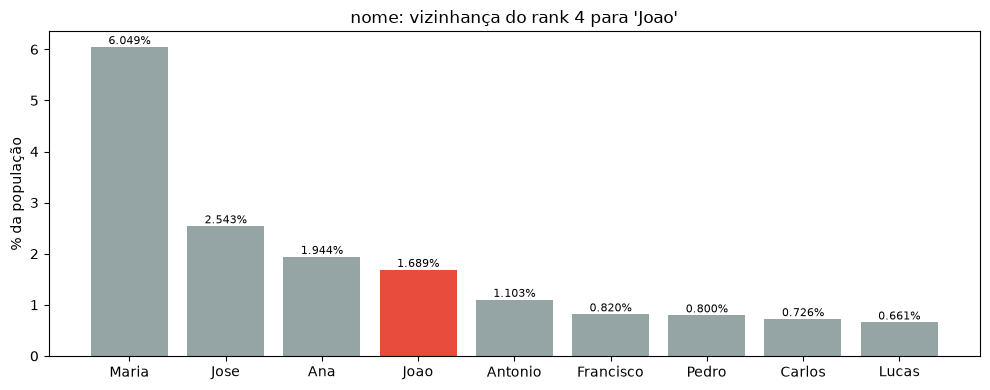

[sobrenome] Joao: rank 536, frequência 36,134, 0.0178% da população


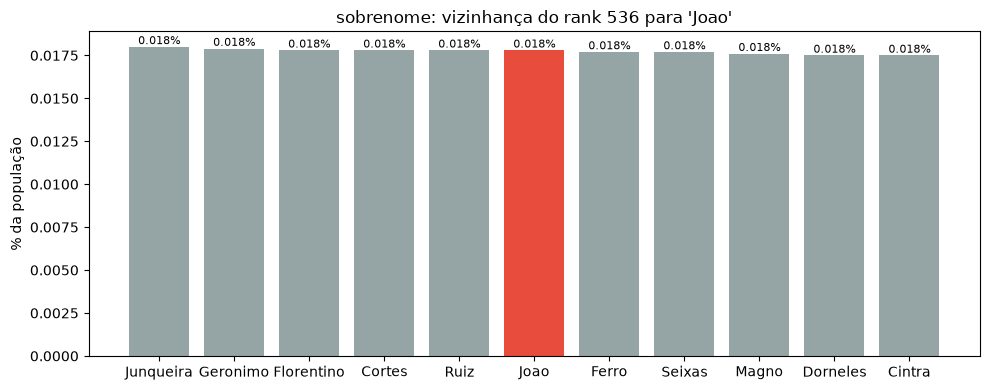

[nome] Silva: rank 1122, frequência 18,419, 0.0091% da população


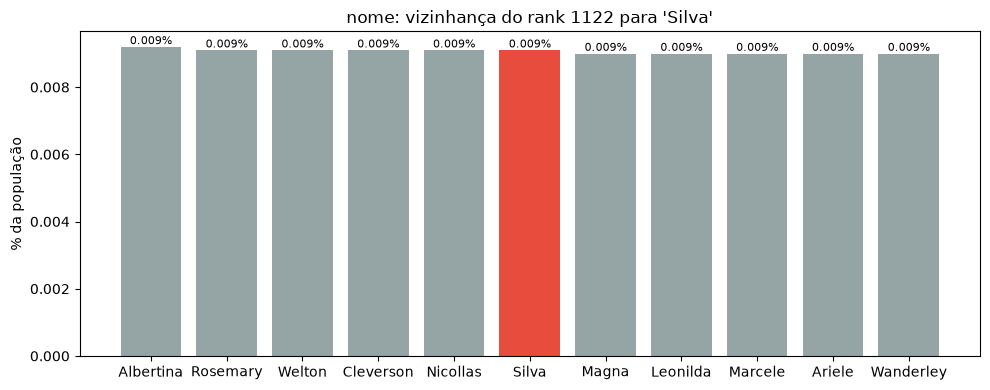

[sobrenome] Silva: rank 1, frequência 34,030,104, 16.7569% da população


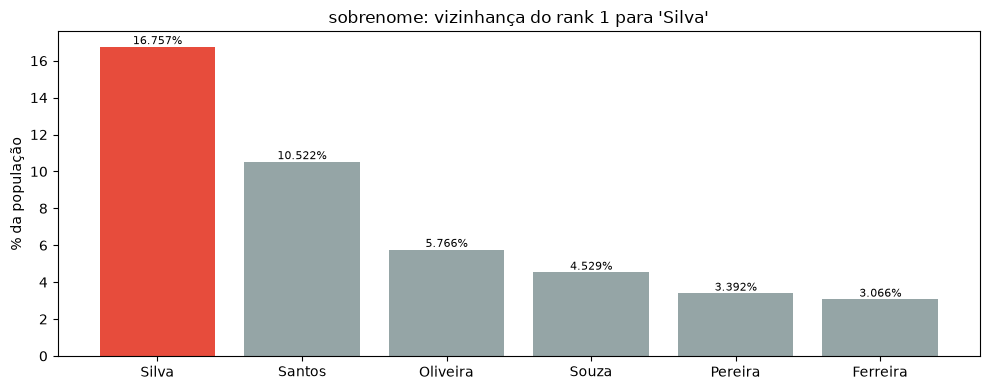

[nome] Pereira: rank 21390, frequência 255, 0.0001% da população


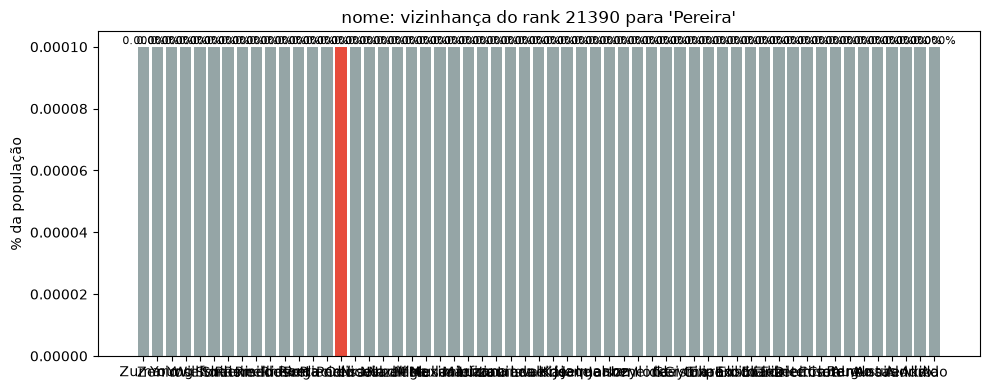

[sobrenome] Pereira: rank 5, frequência 6,888,212, 3.3919% da população


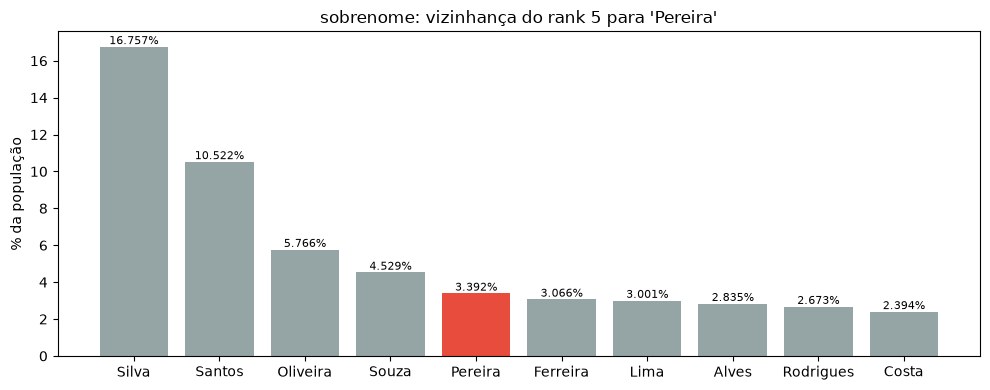

In [3]:
def lookup(term, table, label, window=5):
    term = term.lower()
    if term not in table.index:
        print(f"[{label}] '{term}' não encontrado (IBGE suprime nomes com menos de 20 portadores).")
        return None
    row = table.loc[term]
    if isinstance(row, pd.DataFrame):  # defensive: duplicated key
        row = row.iloc[0]
    print(f"[{label}] {term.title()}: rank {int(row['rank'])}, "
          f"frequência {int(row['frequencia']):,}, {row['percent']}% da população")
    pos = int(row["rank"])
    lo, hi = max(pos - window, 1), pos + window
    nb = table[(table["rank"] >= lo) & (table["rank"] <= hi)]
    colors = ["#e74c3c" if n == term else "#95a5a6" for n in nb["nome"]]
    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(nb["nome"].str.title(), nb["percent"], color=colors)
    ax.bar_label(bars, fmt="%.3f%%", fontsize=8)
    ax.set_title(f"{label}: vizinhança do rank {pos} para '{term.title()}'")
    ax.set_ylabel("% da população")
    plt.tight_layout()
    plt.show()
    return row

# Each term is checked in BOTH rankings, because e.g. 'silva' is a surname
# and also a first name.
results = []  # (termo, tipo, linha)
for q in QUERY:
    for label, table in (("nome", nomes), ("sobrenome", sob)):
        row = lookup(q, table, label)
        if row is not None:
            results.append((q, label, row))


In [4]:
# Compare the percent of the queried names side by side
comp = pd.DataFrame(
    [{"termo": q, "tipo": t, "rank": int(r["rank"]), "frequencia": int(r["frequencia"]),
      "percent": float(r["percent"])} for q, t, r in results]
)
comp

,termo,tipo,rank,frequencia,percent
0,maria,nome,1,12284478,6.0491
1,maria,sobrenome,53,970996,0.4781
2,joao,nome,4,3430608,1.6893
3,joao,sobrenome,536,36134,0.0178
4,silva,nome,1122,18419,0.0091
5,silva,sobrenome,1,34030104,16.7569
6,pereira,nome,21390,255,0.0001
7,pereira,sobrenome,5,6888212,3.3919


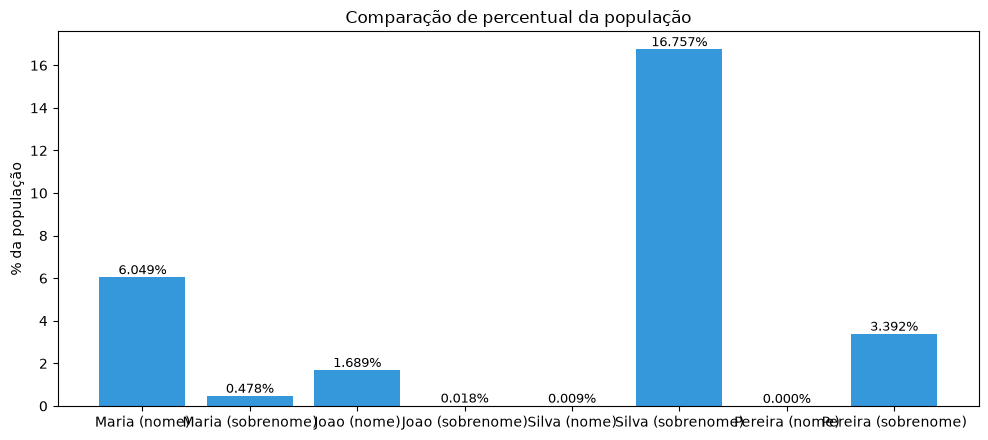

In [5]:
if len(comp):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    labels = [f"{t} ({k})" for t, k in zip(comp["termo"].str.title(), comp["tipo"])]
    bars = ax.bar(labels, comp["percent"], color="#3498db")
    ax.bar_label(bars, fmt="%.3f%%", fontsize=9)
    ax.set_title("Comparação de percentual da população")
    ax.set_ylabel("% da população")
    plt.tight_layout()
    plt.show()